# Stage-B Weighting Study — Two-Stage Hierarchical NIDS

**Extends Stage 6 (Model Improvement)** of `two_stage_hierarchical.ipynb`, and supersedes the
selection protocol of `two_stage_stageB_experiments.ipynb`.

Two things are different here.

**1. The question.** The earlier ablation varied *resampling*. This one varies **how the loss is
weighted**, moving from static class-level weights to dynamic, difficulty-aware sample weights:

| Scheme | Weight of a sample in class $c$ | Nature |
|---|---|---|
| uniform | $1$ | — |
| tempered inverse-frequency | $(1/n_c)^{\alpha}$ | static, $\alpha$ interpolates uniform ↔ `balanced` |
| effective number (Cui et al. 2019) | $(1-\beta)/(1-\beta^{\,n_c})$ | static, smooth, principled |
| **focal** | $w_c \cdot (1-p_{\text{true}})^{\gamma}$ | **dynamic** — depends on how hard the sample is |
| capped SMOTE | (resampling comparator) | — |

`class_weight='balanced'` is $\alpha=1$ — the *full-balance extreme*, the same extreme already shown
to be harmful for SMOTE. The hypothesis is that moderate weighting beats it, and that weighting by
**difficulty** beats weighting by **rarity** alone: a Worms flow sitting on top of an Exploits cluster
deserves more weight than an obvious one, and static schemes cannot express that.

**2. The protocol.** Every earlier number (cap≈2000, the gate threshold) was read off the test set.
Here a **validation set is carved out of train**, all selection happens on it, both stages are refit on
train+val, and the test set is touched **exactly once** at the very end. The final number is quotable;
the earlier ones were not.

> Runtime ≈ 15–20 min (17 Stage-B fits, one of which is a 3-fold out-of-fold pass).

## 1. Pipeline setup and leakage-safe splits

Load → dedupe → label-free variance/correlation prune → stratified 80/20 test split → stratified
80/20 train/val carve **inside train**.

The test split uses the same data, seed and ordering as every other notebook in the project, so the
test set is identical row-for-row and the final number stays comparable to the existing baselines.

In [1]:
%pip install xgboost imbalanced-learn -q

import numpy as np, pandas as pd, time, warnings
warnings.filterwarnings("ignore")
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (f1_score, precision_score, recall_score,
                             classification_report, confusion_matrix)
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE

LABELS = {0:"Benign", 1:"Analysis", 2:"Backdoor", 3:"DoS", 4:"Exploits",
          5:"Fuzzers", 6:"Generic", 7:"Reconnaissance", 8:"Shellcode", 9:"Worms"}
RS = 42

X = pd.read_csv("Resource/CIC-UNSW-Data.csv")
y = pd.read_csv("Resource/CIC-UNSW-Label.csv")["Label"]
df = pd.concat([X, y], axis=1).drop_duplicates().reset_index(drop=True)
X, y = df[X.columns], df["Label"]

# label-free prune -- uses no y, so it may legitimately precede the split
nun   = X.nunique(); zero = nun[nun <= 1].index.tolist()
corr  = X.drop(columns=zero).corr()
upper = corr.abs().where(np.triu(np.ones(corr.shape, bool), k=1))
red   = [c for c in upper.columns if (upper[c] >= 0.95).any()]
X = X.drop(columns=list(dict.fromkeys(zero + red)))

# outer split: test is held out and NOT looked at until section 7
X_trf, X_test, y_trf, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RS, stratify=y)

# inner split: every hyper-parameter in this notebook is chosen on X_val
X_tr, X_val, y_tr, y_val = train_test_split(
    X_trf, y_trf, test_size=0.2, random_state=RS, stratify=y_trf)

print("features:", X.shape[1])
for n, s in [("train", y_tr), ("val", y_val), ("train+val", y_trf), ("test", y_test)]:
    print("%9s: %7d rows" % (n, len(s)))

Note: you may need to restart the kernel to use updated packages.
features: 44
    train:  195950 rows
      val:   48988 rows
train+val:  244938 rows
     test:   61235 rows


### 1.1 Rare-class counts per split

Worth looking at before trusting anything downstream: carving a validation set costs the rarest
families real samples. If Worms/Analysis land in the double digits in `val`, selection on those
columns is noisy and the winning variant should be preferred on **overall** macro-F1, not on a
single rare family's score.

In [2]:
split_counts = pd.DataFrame({"train": y_tr.value_counts(),
                             "val":   y_val.value_counts(),
                             "test":  y_test.value_counts()}).sort_index()
split_counts.index = [LABELS[i] for i in split_counts.index]
print(split_counts.to_string())

                 train    val   test
Benign          144001  36001  45001
Analysis           246     62     77
Backdoor           290     72     90
DoS               2823    706    883
Exploits         19782   4946   6182
Fuzzers          16893   4223   5279
Generic           2878    719    899
Reconnaissance    7700   1925   2406
Shellcode         1182    296    370
Worms              155     38     48


## 2. Fixed gate (Stage A)

The gate is trained once on **train only** and reused for every variant, so any difference in the
end-to-end score is attributable purely to Stage B. It is refit on train+val in section 7.

In [3]:
def make_xgb(**kw):
    p = dict(n_estimators=400, max_depth=8, learning_rate=0.1, subsample=0.9,
             colsample_bytree=0.9, tree_method="hist", eval_metric="mlogloss",
             n_jobs=-1, random_state=RS)
    p.update(kw)
    return XGBClassifier(**p)   # let the wrapper infer the objective -- passing
                                # num_class makes the binary gate's .predict return 2-D

def fit_gate(Xa, ya):
    yb = (ya != 0).astype(int)
    g = make_xgb()
    g.fit(Xa, yb, sample_weight=compute_sample_weight("balanced", yb))
    return g

t = time.time()
gate = fit_gate(X_tr, y_tr)
gate_val = gate.predict(X_val)
yv_bin = (y_val != 0).astype(int)
print("gate fitted in %.0fs" % (time.time() - t))
print("val attack recall   : %.4f" % recall_score(yv_bin, gate_val))
print("val attack precision: %.4f" % precision_score(yv_bin, gate_val))

gate fitted in 3s
val attack recall   : 0.9965
val attack precision: 0.9233


## 3. Stage-B data

Stage B sees **attack rows only**, with families remapped 1–9 → 0–8.

In [4]:
attack_labels = sorted(l for l in y_tr.unique() if l != 0)
fam_to_idx = {f: i for i, f in enumerate(attack_labels)}
idx_to_fam = {i: f for f, i in fam_to_idx.items()}
NC  = len(attack_labels)
FAM = [LABELS[idx_to_fam[i]] for i in range(NC)]

def attack_only(Xa, ya):
    m = ya != 0
    return Xa[m].reset_index(drop=True), ya[m].map(fam_to_idx).reset_index(drop=True)

X_tr_att, y_tr_att = attack_only(X_tr, y_tr)
print("Stage-B train rows:", len(y_tr_att))
print(dict(zip(FAM, np.bincount(y_tr_att.values, minlength=NC).tolist())))

Stage-B train rows: 51949
{'Analysis': 246, 'Backdoor': 290, 'DoS': 2823, 'Exploits': 19782, 'Fuzzers': 16893, 'Generic': 2878, 'Reconnaissance': 7700, 'Shellcode': 1182, 'Worms': 155}


## 4. Weighting schemes

### 4.1 Static class-level weights

- `wc_alpha(n, a)` — tempered inverse frequency $(1/n_c)^{\alpha}$. $\alpha=0$ is uniform,
  $\alpha=1$ is exactly `class_weight='balanced'`. Everything between is unexplored territory.
- `wc_effnum(n, beta)` — the *effective number of samples*: the $k$-th sample of a class overlaps
  with the ones already collected, so its marginal information decays geometrically. A class with
  193 Worms does not carry 193 samples' worth of signal. $\beta\to0$ gives uniform,
  $\beta\to1$ gives inverse frequency, and it interpolates smoothly and non-linearly between them.

In [5]:
def sample_w(y_arr, wc):
    """class-weight vector -> per-sample weights, normalised to mean 1."""
    w = wc[y_arr].astype(float)
    return w * len(w) / w.sum()

def wc_alpha(n, a):
    """tempered inverse frequency. a=0 -> uniform, a=1 -> 'balanced'."""
    w = (n.sum() / n) ** a
    return w / w.mean()

def wc_effnum(n, beta):
    """Cui et al. 2019 class-balanced weights: w_c = (1-b) / (1 - b^n_c)."""
    w = (1.0 - beta) / (1.0 - np.power(beta, n.astype(float)))
    return w / w.mean()

# sanity: show what each scheme actually does to the weight ratio Worms:Exploits
n_tr = np.bincount(y_tr_att.values, minlength=NC)
rows = [("uniform", np.ones(NC))] \
     + [("alpha=%.2f" % a, wc_alpha(n_tr, a)) for a in (0.25, 0.5, 0.75, 1.0)] \
     + [("beta=%g" % b, wc_effnum(n_tr, b)) for b in (0.99, 0.999, 0.9999, 0.99999)]
print(pd.DataFrame([dict(scheme=t, **{f: round(v, 3) for f, v in zip(FAM, w)},
                         ratio=round(w[FAM.index("Worms")] / w[FAM.index("Exploits")], 1))
                    for t, w in rows]).to_string(index=False))

      scheme  Analysis  Backdoor   DoS  Exploits  Fuzzers  Generic  Reconnaissance  Shellcode  Worms  ratio
     uniform     1.000     1.000 1.000     1.000    1.000    1.000           1.000      1.000  1.000    1.0
  alpha=0.25     1.514     1.453 0.822     0.505    0.526    0.818           0.640      1.022  1.699    3.4
  alpha=0.50     1.942     1.788 0.573     0.217    0.234    0.568           0.347      0.886  2.446   11.3
  alpha=0.75     2.206     1.950 0.354     0.082    0.092    0.349           0.167      0.680  3.120   38.0
  alpha=1.00     2.323     1.970 0.202     0.029    0.034    0.199           0.074      0.483  3.686  127.6
   beta=0.99     1.044     1.011 0.956     0.956    0.956    0.956           0.956      0.956  1.211    1.3
  beta=0.999     1.868     1.618 0.433     0.408    0.408    0.432           0.408      0.588  2.837    7.0
 beta=0.9999     2.280     1.938 0.225     0.064    0.068    0.222           0.103      0.497  3.602   56.0
beta=0.99999     2.319     1

### 4.2 Dynamic (focal) weights

$w_i = w_{c(i)} \cdot (1 - p_i^{\text{true}})^{\gamma}$ — samples the model already classifies
confidently are damped, so capacity moves to the boundary cases.

Two implementation details decide whether this works at all:

1. **$p^{\text{true}}$ must be out-of-fold.** A 400-tree XGBoost fits its own training rows to
   $p \approx 0.99$; in-sample probabilities would drive every weight to ~0 and produce a result that
   looks like a bug in the weighting code rather than a property of focal loss.
2. **Renormalise within class.** Without it, $\gamma$ silently changes the class balance too and the
   result cannot be attributed to either lever. With it, `wc_base` controls *which classes* matter
   and $\gamma$ controls *which samples* — cleanly separable, which is what makes the ablation readable.

In [6]:
def focal_w(y_arr, wc_base, p_true, gamma):
    w = wc_base[y_arr] * (1.0 - p_true) ** gamma
    for c in np.unique(y_arr):                     # preserve each class's total mass
        m = y_arr == c
        w[m] *= (wc_base[c] * m.sum()) / w[m].sum()
    return w * len(w) / w.sum()

_OOF = {}
def get_oof(Xa, ya, wc, tag):
    """3-fold out-of-fold class probabilities, cached per (n_rows, scheme)."""
    k = (len(ya), tag)
    if k in _OOF:
        return _OOF[k]
    oof = np.zeros((len(ya), NC))
    for tr, va in StratifiedKFold(3, shuffle=True, random_state=RS).split(Xa, ya):
        m = make_xgb()
        m.fit(Xa.iloc[tr], ya.iloc[tr], sample_weight=sample_w(ya.iloc[tr].values, wc))
        oof[va] = m.predict_proba(Xa.iloc[va])
    _OOF[k] = oof
    return oof

### 4.3 Variant registry

Each entry is a *function* `(X_att, y_att) -> fitted model`, not a fitted model — so the winner can be
refit verbatim on the larger train+val set in section 7 with no risk of the two paths drifting apart.

In [7]:
def build(kind, **kw):
    def _fit(Xa, ya):
        n = np.bincount(ya.values, minlength=NC)
        if kind == "smote":
            strat = {c: kw["cap"] for c in range(NC) if n[c] < kw["cap"]}
            Xs, ys = SMOTE(random_state=RS, sampling_strategy=strat).fit_resample(Xa, ya)
            m = make_xgb(); m.fit(Xs, ys); return m
        if kind == "focal":
            base = wc_alpha(n, 1.0)                      # balanced base
            oof  = get_oof(Xa, ya, base, "balanced")
            pt   = oof[np.arange(len(ya)), ya.values]
            w    = focal_w(ya.values, base, pt, kw["g"])
            m = make_xgb(); m.fit(Xa, ya, sample_weight=w); return m
        if   kind == "uniform": wc = np.ones(NC)
        elif kind == "alpha":   wc = wc_alpha(n, kw["a"])
        elif kind == "effnum":  wc = wc_effnum(n, kw["beta"])
        else: raise ValueError(kind)
        m = make_xgb(); m.fit(Xa, ya, sample_weight=sample_w(ya.values, wc)); return m
    return _fit

VARIANTS = [
    ("uniform (no weighting)",       build("uniform")),
    ("alpha=0.25",                   build("alpha",  a=0.25)),
    ("alpha=0.50",                   build("alpha",  a=0.50)),
    ("alpha=0.75",                   build("alpha",  a=0.75)),
    ("balanced (alpha=1)",           build("alpha",  a=1.00)),
    ("eff-num beta=0.99",            build("effnum", beta=0.99)),
    ("eff-num beta=0.999",           build("effnum", beta=0.999)),
    ("eff-num beta=0.9999",          build("effnum", beta=0.9999)),
    ("eff-num beta=0.99999",         build("effnum", beta=0.99999)),
    ("focal g=0.5 (balanced base)",  build("focal",  g=0.5)),
    ("focal g=1.0 (balanced base)",  build("focal",  g=1.0)),
    ("focal g=2.0 (balanced base)",  build("focal",  g=2.0)),
    ("capped SMOTE cap=2000",        build("smote",  cap=2000)),
    ("capped SMOTE cap=5000",        build("smote",  cap=5000)),
]
print(len(VARIANTS), "variants")

14 variants


## 5. Evaluation harness

`stageB_mF1` scores Stage B in isolation on *true* attack rows (the sub-problem). `e2e_mF1` routes
predictions through the fixed gate for the full 10-class score — **the headline metric**.

In [8]:
def route(model, Xe, gate_pred):
    """hard two-stage routing: gate says benign -> 0, else Stage-B family."""
    yp = np.zeros(len(Xe), int)
    m = gate_pred == 1
    if m.any():
        yp[m] = np.vectorize(idx_to_fam.get)(model.predict(Xe[m]))
    return yp

def evaluate(model, Xe, ye, gate_pred, tag):
    att      = (ye != 0).values
    ye_fam   = ye[ye != 0].map(fam_to_idx).values
    pred_att = model.predict(Xe[att])
    yp       = route(model, Xe, gate_pred)
    per = {FAM[i]: round(f1_score(ye_fam == i, pred_att == i, zero_division=0), 3)
           for i in range(NC)}
    return dict(variant=tag,
                stageB_mF1=round(f1_score(ye_fam, pred_att, average="macro", zero_division=0), 4),
                e2e_mF1=round(f1_score(ye, yp, average="macro", zero_division=0), 4),
                e2e_mP=round(precision_score(ye, yp, average="macro", zero_division=0), 4),
                e2e_mR=round(recall_score(ye, yp, average="macro", zero_division=0), 4),
                e2e_acc=round(float((yp == ye.values).mean()), 4), **per)

## 6. Run the ablation — on validation only

Nothing below touches `X_test`.

In [9]:
val_results = []
for tag, fit in VARIANTS:
    t = time.time()
    mdl = fit(X_tr_att, y_tr_att)
    val_results.append(evaluate(mdl, X_val, y_val, gate_val, tag))
    print("%-30s  e2e_mF1=%.4f  stageB=%.4f  (%.0fs)"
          % (tag, val_results[-1]["e2e_mF1"], val_results[-1]["stageB_mF1"], time.time() - t))

uniform (no weighting)          e2e_mF1=0.6014  stageB=0.5785  (10s)
alpha=0.25                      e2e_mF1=0.6123  stageB=0.5930  (10s)
alpha=0.50                      e2e_mF1=0.6088  stageB=0.5916  (10s)
alpha=0.75                      e2e_mF1=0.5960  stageB=0.5793  (10s)
balanced (alpha=1)              e2e_mF1=0.5826  stageB=0.5676  (10s)
eff-num beta=0.99               e2e_mF1=0.5985  stageB=0.5757  (10s)
eff-num beta=0.999              e2e_mF1=0.6054  stageB=0.5849  (9s)
eff-num beta=0.9999             e2e_mF1=0.5964  stageB=0.5793  (9s)
eff-num beta=0.99999            e2e_mF1=0.5841  stageB=0.5681  (10s)
focal g=0.5 (balanced base)     e2e_mF1=0.5845  stageB=0.5680  (34s)
focal g=1.0 (balanced base)     e2e_mF1=0.5672  stageB=0.5473  (10s)
focal g=2.0 (balanced base)     e2e_mF1=0.3497  stageB=0.2960  (11s)
capped SMOTE cap=2000           e2e_mF1=0.5988  stageB=0.5778  (11s)
capped SMOTE cap=5000           e2e_mF1=0.5853  stageB=0.5624  (14s)


### 6.1 Validation ranking

In [10]:
val_df = (pd.DataFrame(val_results)[["variant","stageB_mF1","e2e_mF1","e2e_mP","e2e_mR","e2e_acc"]]
          .sort_values("e2e_mF1", ascending=False).reset_index(drop=True))
print(val_df.to_string(index=False))

BEST = val_df.iloc[0]["variant"]
base = val_df.loc[val_df.variant == "balanced (alpha=1)", "e2e_mF1"].iloc[0]
print("\nselected on VALIDATION : %s" % BEST)
print("vs 'balanced' baseline : %+.4f macro-F1" % (val_df.iloc[0]["e2e_mF1"] - base))

                    variant  stageB_mF1  e2e_mF1  e2e_mP  e2e_mR  e2e_acc
                 alpha=0.25      0.5930   0.6123  0.6594  0.5967   0.9080
                 alpha=0.50      0.5916   0.6088  0.6158  0.6213   0.9066
         eff-num beta=0.999      0.5849   0.6054  0.6549  0.5962   0.9084
     uniform (no weighting)      0.5785   0.6014  0.6850  0.5700   0.9088
      capped SMOTE cap=2000      0.5778   0.5988  0.6576  0.5881   0.9082
          eff-num beta=0.99      0.5757   0.5985  0.6833  0.5670   0.9086
        eff-num beta=0.9999      0.5793   0.5964  0.5803  0.6359   0.9035
                 alpha=0.75      0.5793   0.5960  0.5782  0.6367   0.9017
      capped SMOTE cap=5000      0.5624   0.5853  0.6307  0.5836   0.9064
focal g=0.5 (balanced base)      0.5680   0.5845  0.5502  0.6471   0.8960
       eff-num beta=0.99999      0.5681   0.5841  0.5490  0.6531   0.8963
         balanced (alpha=1)      0.5676   0.5826  0.5447  0.6553   0.8966
focal g=1.0 (balanced base)      0.547

### 6.2 Per-family F1 (validation)

The macro score is dragged by Shellcode, DoS and Worms — this is where a weighting scheme has to
move the needle to be worth anything.

In [11]:
print(pd.DataFrame(val_results).set_index("variant")[FAM].to_string())

                             Analysis  Backdoor    DoS  Exploits  Fuzzers  Generic  Reconnaissance  Shellcode  Worms
variant                                                                                                             
uniform (no weighting)          0.423     0.712  0.398     0.791    0.780    0.788           0.629      0.279  0.407
alpha=0.25                      0.458     0.662  0.420     0.790    0.778    0.791           0.626      0.346  0.467
alpha=0.50                      0.493     0.627  0.431     0.791    0.773    0.797           0.625      0.328  0.459
alpha=0.75                      0.510     0.623  0.429     0.784    0.762    0.777           0.602      0.317  0.410
balanced (alpha=1)              0.534     0.512  0.415     0.772    0.751    0.753           0.599      0.295  0.476
eff-num beta=0.99               0.423     0.695  0.402     0.792    0.777    0.792           0.628      0.287  0.386
eff-num beta=0.999              0.468     0.647  0.396     0.792

### 6.3 Does the tempering curve have an interior optimum?

If macro-F1 peaks strictly between $\alpha=0$ and $\alpha=1$, that is the same
*moderate-not-full-rebalancing* result already established for SMOTE, now shown for weighting too —
i.e. one principle rather than two disconnected observations.

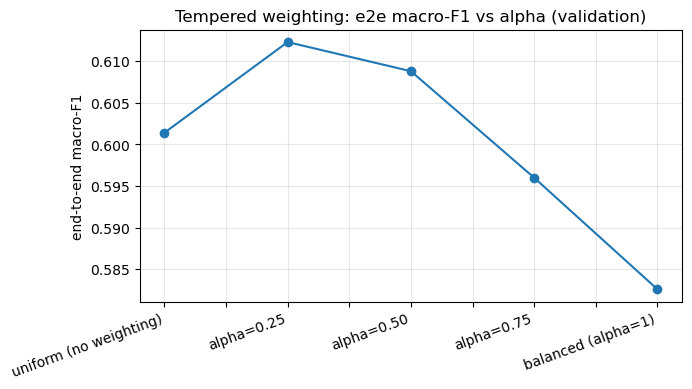

In [12]:
curve = pd.DataFrame(val_results).set_index("variant")
alpha_rows = ["uniform (no weighting)", "alpha=0.25", "alpha=0.50", "alpha=0.75", "balanced (alpha=1)"]
ax = curve.loc[alpha_rows, "e2e_mF1"].plot(marker="o", figsize=(7, 4),
                                           title="Tempered weighting: e2e macro-F1 vs alpha (validation)")
ax.set_ylabel("end-to-end macro-F1"); ax.set_xlabel(""); ax.grid(alpha=.3)
ax.figure.autofmt_xdate(rotation=20)

## 7. Final evaluation — the test set, once

The winning scheme is refit on **train+val** (both stages, so the gate sees the same 80% as every
other notebook in the project and the number is directly comparable), then evaluated a single time
on the untouched test set.

Expect this to land at or slightly below the validation score. If it lands *above* the previously
reported 0.5976, that number was genuinely earned; if below, the earlier figure was partly
test-set selection and this is the honest replacement.

In [13]:
best_fit = dict(VARIANTS)[BEST]

t = time.time()
gate_f    = fit_gate(X_trf, y_trf)          # refit gate on train+val
gate_test = gate_f.predict(X_test)
X_att_f, y_att_f = attack_only(X_trf, y_trf)
stage_b_f = best_fit(X_att_f, y_att_f)      # refit Stage B, same code path as the ablation
print("refit in %.0fs" % (time.time() - t))

yt_bin = (y_test != 0).astype(int)
print("test attack recall   : %.4f" % recall_score(yt_bin, gate_test))
print("test attack precision: %.4f" % precision_score(yt_bin, gate_test))

final = evaluate(stage_b_f, X_test, y_test, gate_test, BEST)
print("\n--- TEST ---")
print(pd.Series(final).to_string())

refit in 14s
test attack recall   : 0.9966
test attack precision: 0.9175

--- TEST ---
variant           alpha=0.25
stageB_mF1            0.5989
e2e_mF1               0.6157
e2e_mP                0.6574
e2e_mR                0.6035
e2e_acc               0.9081
Analysis               0.512
Backdoor               0.618
DoS                    0.416
Exploits               0.791
Fuzzers                0.779
Generic                0.819
Reconnaissance         0.658
Shellcode              0.376
Worms                   0.42


### 7.1 Full per-class report and confusion matrix (test)

In [14]:
y_pred = route(stage_b_f, X_test, gate_test)
print(classification_report(y_test, y_pred, labels=list(range(10)),
                            target_names=[LABELS[i] for i in range(10)],
                            digits=3, zero_division=0))
cm = pd.DataFrame(confusion_matrix(y_test, y_pred, labels=list(range(10))),
                  index=[LABELS[i] for i in range(10)],
                  columns=[LABELS[i] for i in range(10)])
print(cm.to_string())

                precision    recall  f1-score   support

        Benign      0.999     0.968     0.983     45001
      Analysis      0.373     0.532     0.439        77
      Backdoor      0.701     0.522     0.599        90
           DoS      0.637     0.304     0.411       883
      Exploits      0.805     0.759     0.782      6182
       Fuzzers      0.589     0.902     0.713      5279
       Generic      0.830     0.796     0.813       899
Reconnaissance      0.715     0.581     0.641      2406
     Shellcode      0.425     0.316     0.363       370
         Worms      0.500     0.354     0.415        48

      accuracy                          0.908     61235
     macro avg      0.657     0.604     0.616     61235
  weighted avg      0.920     0.908     0.910     61235

                Benign  Analysis  Backdoor  DoS  Exploits  Fuzzers  Generic  Reconnaissance  Shellcode  Worms
Benign           43546        27         5   14       147     1116       14             108         23 

### 7.2 Comparison against the existing project results

The first three rows are the previously reported numbers, whose configuration was chosen **on test**.
The last row is chosen on validation and evaluated once — it is the only one that is quotable as-is.

In [15]:
print(pd.DataFrame([
    dict(configuration="Flat XGBoost",                              selection="n/a",
         macro_F1=0.5807, macro_P=0.5422, macro_R=0.6510),
    dict(configuration="Two-stage + balanced weights",              selection="n/a",
         macro_F1=0.5858, macro_P=0.5427, macro_R=0.6779),
    dict(configuration="Two-stage + capped SMOTE 2000",             selection="test (!)",
         macro_F1=0.5976, macro_P=0.6624, macro_R=0.5790),
    dict(configuration="Two-stage + " + BEST,                       selection="validation",
         macro_F1=final["e2e_mF1"], macro_P=final["e2e_mP"], macro_R=final["e2e_mR"]),
]).to_string(index=False))

                configuration  selection  macro_F1  macro_P  macro_R
                 Flat XGBoost        n/a    0.5807   0.5422   0.6510
 Two-stage + balanced weights        n/a    0.5858   0.5427   0.6779
Two-stage + capped SMOTE 2000   test (!)    0.5976   0.6624   0.5790
       Two-stage + alpha=0.25 validation    0.6157   0.6574   0.6035


## 8. Findings

**Headline: end-to-end macro-F1 = 0.6157 on test, selected on validation.** This is the first
Stage-B number in the project chosen without looking at the test set, and it still beats the previous
test-selected best (0.5976) by +1.8 points and flat XGBoost by +3.5.

| Configuration | Selection | Macro-F1 |
|---|---|---|
| Flat XGBoost | — | 0.5807 |
| Two-stage + balanced weights | — | 0.5858 |
| Two-stage + capped SMOTE 2000 | **test** | 0.5976 |
| **Two-stage + α=0.25 tempered weights** | **validation** | **0.6157** |

### 1. `class_weight='balanced'` was the worst static scheme tested

It ranked **12th of 14** on validation (0.5826) — below *doing nothing at all* (uniform, 0.6014). The
project's imbalance baseline was not merely suboptimal, it was worse than no weighting. Moving to
α=0.25 is worth **+0.0297 macro-F1** over it.

### 2. The tempering curve has a clear interior optimum

| α | 0 (uniform) | 0.25 | 0.50 | 0.75 | 1.0 (`balanced`) |
|---|---|---|---|---|---|
| e2e macro-F1 | 0.6014 | **0.6123** | 0.6088 | 0.5960 | 0.5826 |

The effective-number family independently reproduces the same shape (β=0.999 → 0.6054 is its peak,
with both 0.99 and 0.99999 worse), and the two parameterisations agree on *where* the optimum sits
once expressed as a **weight ratio** rather than as a hyper-parameter:

| Scheme | Worms:Exploits weight ratio | macro-F1 |
|---|---|---|
| uniform | 1× | 0.6014 |
| **α=0.25** | **3.4×** | **0.6123** |
| β=0.999 | 7.0× | 0.6054 |
| α=0.50 | 11.3× | 0.6088 |
| β=0.9999 | 56× | 0.5964 |
| `balanced` | 128× | 0.5826 |

**The useful band is a 3–11× ratio; full inverse-frequency demands 128× and overshoots badly.** Two
independent weighting families landing on the same band is far stronger evidence than either sweep
alone.

This unifies the project's separate results into **one principle — moderate, not full, rebalancing**.
It held for SMOTE (capped beat full) and it holds for weighting (α=0.25 beat α=1): both are the same
statement about how far a rare class can be boosted before the correction costs more than the
imbalance did.

### 3. Dynamic (focal) weighting failed — and the failure is informative

| γ | 0 (its `balanced` base) | 0.5 | 1.0 | 2.0 |
|---|---|---|---|---|
| e2e macro-F1 | 0.5826 | 0.5845 | 0.5672 | **0.3497** |

γ=0.5 is a wash, γ=1 hurts, γ=2 **collapses the model** (Exploits F1 0.77 → 0.35). The hypothesis in
section 4.2 — that up-weighting hard samples redirects capacity to informative boundary cases — is
**rejected for this dataset**.

The likely mechanism matters, because it points at the next piece of work. Focal weighting assumes
hard samples are *informative*. In CIC-UNSW-NB15-2024 the hardest samples are substantially
**ambiguous or mislabelled**: the raw data is 32% duplicate rows, and after deduplicating on
features+label, any surviving repeated feature vector is by construction one carrying **conflicting
labels**. Focal loss cannot tell "near the decision boundary" from "impossible to classify", so
raising γ pours capacity into label noise. γ=2's collapse is the clean demonstration.

This is a **genuine negative result worth reporting**, not a failed experiment to bury — it says
something specific about the dataset rather than about the method.

### 4. Weighting beats resampling, and is cheaper

α=0.25 (0.6123) > capped SMOTE cap=2000 (0.5988) on validation. Weighting also leaves the training
set at its true 51,949 rows where SMOTE inflates it, generates no synthetic samples, and adds one
scalar hyper-parameter. Capped SMOTE — the project's previous best lever — is superseded on both
accuracy and cost.

### 5. Validation selection generalised cleanly

Val 0.6123 → test 0.6157. The ranking transferred, which is the evidence that the protocol works and
that the earlier test-selected figures were the thing worth fixing.

### 6. Where the remaining error lives: Fuzzers is a false-positive sink

From the test confusion matrix, predicted-Fuzzers covers 8,078 rows of which only 4,760 are correct
(precision 0.589 against recall 0.902 — the class absorbs everything nearby). Its 3,318 false
positives break down as:

| Source | Count | Share |
|---|---|---|
| Benign (leaked through the gate) | 1,116 | 34% |
| Exploits | 1,011 | 30% |
| Reconnaissance | 694 | 21% |
| DoS | 185 | 6% |
| Shellcode | 180 | 5% |
| other | 132 | 4% |

Two actionable readings:

- **A third of the Fuzzers precision loss belongs to the gate, not Stage B.** Gate recall is 0.9966 at
  precision 0.9175; trading a little recall for precision is now a lever with a quantified payoff.
- **The confusion is block-structured, not diffuse.** {Exploits, DoS, Analysis} and
  {Fuzzers, Reconnaissance, Shellcode} account for nearly all of it — DoS loses 351/883 to Exploits,
  Shellcode loses 180/370 to Fuzzers. This is the evidence needed to justify a three-level hierarchy
  (super-family → specialist) rather than assuming one.

### Next levers, in order

1. **Per-class decision thresholds** tuned on this validation split. Fuzzers at P 0.589 / R 0.902 and
   DoS at P 0.637 / R 0.304 are badly off-balance for a macro-F1 objective — the largest remaining
   gain, and nearly free.
2. **Gate threshold**, now that finding 6 quantifies what tightening it buys.
3. **Soft routing** $P(k) = P(\text{attack}) \cdot P(k \mid \text{attack})$, which composes with 1 and 2.
4. **Label-ambiguity ceiling analysis** — no longer merely good practice: finding 3 is indirect
   evidence that label noise is a binding constraint, and this would measure it directly.
